In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plot
import seaborn as sns
import sqlite3

from google.colab import drive
drive.mount('/content/drive', force_remount=True)
dataset_path = "/content/drive/MyDrive/Ames_Housing_Project/AmesHousing.csv"
df = pd.read_csv(dataset_path)
df.head(10)

Mounted at /content/drive


,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NaN,Reg,Lvl,...,0,NaN,MnPrv,NaN,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NaN,IR1,Lvl,...,0,NaN,MnPrv,NaN,0,3,2010,WD,Normal,189900
5,6,527105030,60,RL,78.0,9978,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,6,2010,WD,Normal,195500
6,7,527127150,120,RL,41.0,4920,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,213500
7,8,527145080,120,RL,43.0,5005,Pave,NaN,IR1,HLS,...,0,NaN,NaN,NaN,0,1,2010,WD,Normal,191500
8,9,527146030,120,RL,39.0,5389,Pave,NaN,IR1,Lvl,...,0,NaN,NaN,NaN,0,3,2010,WD,Normal,236500
9,10,527162130,60,RL,60.0,7500,Pave,NaN,Reg,Lvl,...,0,NaN,NaN,NaN,0,6,2010,WD,Normal,189000


# SQL

In [3]:
# Create an SQLite database
conn = sqlite3.connect('ames_housing.db')

# Import the dataset into an SQL table
df.to_sql('ames_housing', conn, if_exists='replace', index=False)


2930

In [4]:
#allow python execute sql commands
cursor = conn.cursor()

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type='table';
""")
cursor.fetchall()

[('ames_housing',)]

In [5]:
#Inspect schema and extract residential properties
query = """
PRAGMA table_info(ames_housing);
"""
schema = pd.read_sql_query(query, conn)
schema

,cid,name,type,notnull,dflt_value,pk
0,0,Order,INTEGER,0,None,0
1,1,PID,INTEGER,0,None,0
2,2,MS SubClass,INTEGER,0,None,0
3,3,MS Zoning,TEXT,0,None,0
4,4,Lot Frontage,REAL,0,None,0
...,...,...,...,...,...,...
77,77,Mo Sold,INTEGER,0,None,0
78,78,Yr Sold,INTEGER,0,None,0
79,79,Sale Type,TEXT,0,None,0
80,80,Sale Condition,TEXT,0,None,0


In [6]:
#retrieving residential properties
query = """
SELECT *
FROM ames_housing
WHERE "MS Zoning" = 'RL'
AND "Sale Condition" = 'Normal';
"""
residential_homes = pd.read_sql_query(query, conn)
residential_homes.head()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,None,IR1,Lvl,...,0,None,None,None,0,5,2010,WD,Normal,215000
1,3,526351010,20,RL,81.0,14267,Pave,None,IR1,Lvl,...,0,None,None,Gar2,12500,6,2010,WD,Normal,172000
2,4,526353030,20,RL,93.0,11160,Pave,None,Reg,Lvl,...,0,None,None,None,0,4,2010,WD,Normal,244000
3,5,527105010,60,RL,74.0,13830,Pave,None,IR1,Lvl,...,0,None,MnPrv,None,0,3,2010,WD,Normal,189900
4,6,527105030,60,RL,78.0,9978,Pave,None,IR1,Lvl,...,0,None,None,None,0,6,2010,WD,Normal,195500


In [7]:
#Housing statistics by neighborhood
query = """
SELECT
    Neighborhood,
    COUNT(*) AS total_homes,
    ROUND(AVG(SalePrice), 2) AS average_sale_price
FROM ames_housing
GROUP BY Neighborhood
ORDER BY average_sale_price DESC;
"""
neighborhood_analysis = pd.read_sql_query(query, conn)
neighborhood_analysis

,Neighborhood,total_homes,average_sale_price
0,NoRidge,71,330319.13
1,StoneBr,51,324229.20
2,NridgHt,166,322018.27
3,GrnHill,2,280000.00
4,Veenker,24,248314.58
5,Timber,72,246599.54
6,Somerst,182,229707.32
7,ClearCr,44,208662.09
8,Crawfor,103,207550.83
9,CollgCr,267,201803.43


In [8]:
#identifying missing values
query = """
SELECT
    COUNT(*) AS total_records,
    SUM(CASE WHEN "Lot Frontage" IS NULL THEN 1 ELSE 0 END)
        AS missing_lot_frontage,
    SUM(CASE WHEN "Garage Type" IS NULL THEN 1 ELSE 0 END)
        AS missing_garage_type,
    SUM(CASE WHEN "Bsmt Qual" IS NULL THEN 1 ELSE 0 END)
        AS missing_basement_quality,
    SUM(CASE WHEN "Bsmt Cond" IS NULL THEN 1 ELSE 0 END)
        AS missing_basement_condition,
    SUM(CASE WHEN "Bsmt Exposure" IS NULL THEN 1 ELSE 0 END)
        AS missing_basement_exposure,
    SUM(CASE WHEN "BsmtFin Type 1" IS NULL THEN 1 ELSE 0 END)
        AS missing_basement_finishing
FROM ames_housing;
"""
missing_values = pd.read_sql_query(query, conn)
missing_values

,total_records,missing_lot_frontage,missing_garage_type,missing_basement_quality,missing_basement_condition,missing_basement_exposure,missing_basement_finishing
0,2930,490,157,80,80,83,80


PYTHON EDA

count      2930.000000
mean     180796.060068
std       79886.692357
min       12789.000000
25%      129500.000000
50%      160000.000000
75%      213500.000000
max      755000.000000
Name: SalePrice, dtype: float64

Skewness (raw): 1.74
Kurtosis (raw): 5.12
Skewness (log): -0.01


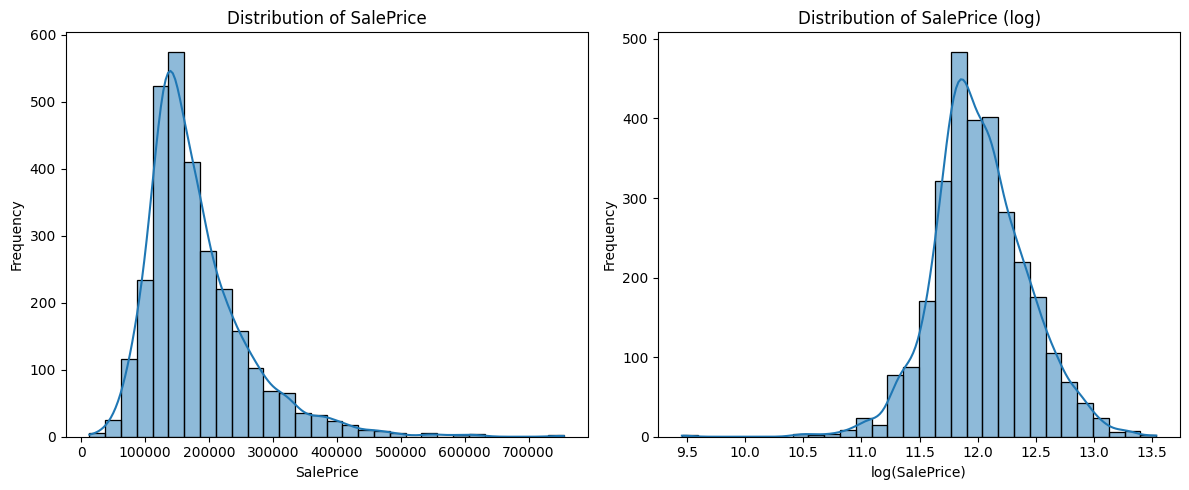

In [9]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


print(df["SalePrice"].describe())
print()

print("Skewness (raw):", round(df["SalePrice"].skew(), 2))
print("Kurtosis (raw):", round(df["SalePrice"].kurt(), 2))
print("Skewness (log):", round(np.log1p(df["SalePrice"]).skew(), 2))


fig, ax = plt.subplots(1, 2, figsize=(12, 5))

sns.histplot(df["SalePrice"], bins=30, kde=True, ax=ax[0])
ax[0].set_title("Distribution of SalePrice")
ax[0].set_xlabel("SalePrice")
ax[0].set_ylabel("Frequency")

sns.histplot(np.log1p(df["SalePrice"]), bins=30, kde=True, ax=ax[1])
ax[1].set_title("Distribution of SalePrice (log)")
ax[1].set_xlabel("log(SalePrice)")
ax[1].set_ylabel("Frequency")

plt.tight_layout()
plt.show()

The average Sale Price is $180,796, while the median Sale Price is $160,000. The mean is higher than the median because a small number of very expensive properties, with the maximum price reaching $755,000, increase the overall average. The Sale Price distribution is positively skewed, with a skewness value of 1.74, indicating that most properties are concentrated at lower to middle price ranges, with fewer high value properties creating a long right tail. The kurtosis value of 5.12 suggests the presence of extreme values compared to a normal distribution. After applying a log transformation, skewness reduced to -0.01, producing a nearly symmetrical distribution. Therefore, a log transformation is recommended during model preprocessing, particularly for Linear Regression.

Neighborhood
StoneBr    319000.0
NridgHt    317750.0
NoRidge    302000.0
GrnHill    280000.0
Veenker    250250.0
Name: SalePrice, dtype: float64


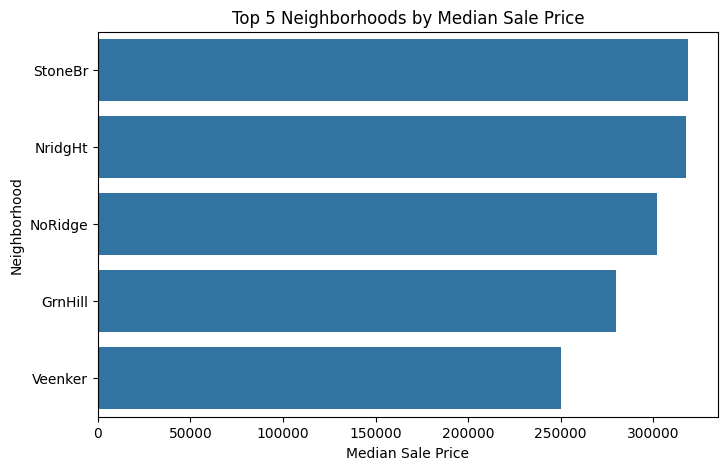

In [10]:
# top 5 neighborhoods by median sale price

top5 = (
    df.groupby("Neighborhood")["SalePrice"]
      .median()
      .sort_values(ascending=False)
      .head(5)
)

print(top5)

plt.figure(figsize=(8,5))
sns.barplot(x=top5.values, y=top5.index)

plt.title("Top 5 Neighborhoods by Median Sale Price")
plt.xlabel("Median Sale Price")
plt.ylabel("Neighborhood")
plt.show()


The five neighborhoods with the highest median sale price are StoneBr($319,000), NridgHt ($317,000), NoRidge ($302,000), GrnHill ($280,000) and Veenker ($250,000).
These values are considerably higher than the overall median sale price of $160,000, showing that location has significant influence on property values. therefore neighborhood is likely to be an important feature in model development.

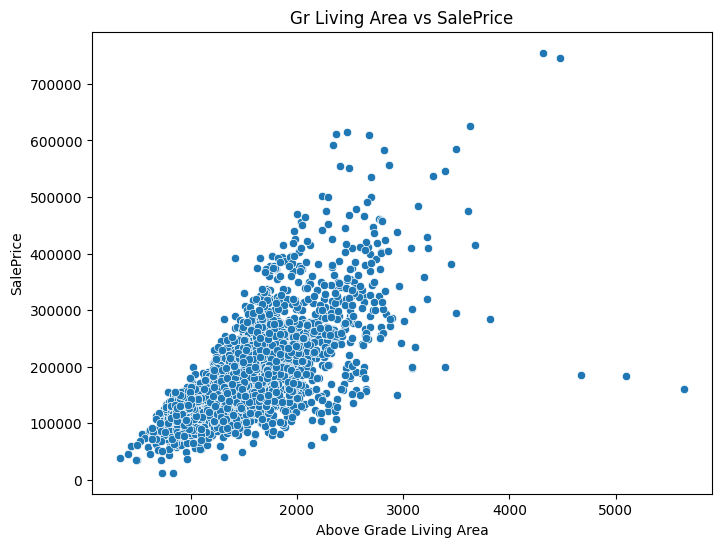

Number of outliers found: 3
      Order  Gr Liv Area  SalePrice
1498   1499         5642     160000
2180   2181         5095     183850
2181   2182         4676     184750


In [11]:
# Looking for outlier

plt.figure(figsize=(8,6))

sns.scatterplot(
    data=df,
    x="Gr Liv Area",
    y="SalePrice"
)

plt.title("Gr Living Area vs SalePrice")
plt.xlabel("Above Grade Living Area")
plt.ylabel("SalePrice")
plt.show()

outliers = df[
    (df["Gr Liv Area"] > 4000) &
    (df["SalePrice"] < 300000)
]

print("Number of outliers found:", len(outliers))
print(outliers[["Order", "Gr Liv Area", "SalePrice"]])

The scatter plot between Gr Liv Area and Sale Price shows a positive relationship, where properties with larger living areas generally have higher prices. However, three potential outliers were identified: Order 1499 (5,642 sq ft at $160,000), Order 2181 (5,095 sq ft at $183,850), and Order 2182 (4,676 sq ft at $184,750). These properties have unusually large living areas compared to their sale prices and may influence model performance.

In [12]:
# cleaning missing values

import pandas as pd
import numpy as np

print("Missing values before cleaning:", df.isnull().sum().sum())

text_columns = df.select_dtypes(include=["object", "string"]).columns
df[text_columns] = df[text_columns].fillna("None")

number_columns = df.select_dtypes(include="number").columns.drop("Lot Frontage")
df[number_columns] = df[number_columns].fillna(0)

df["TotalSqFt"] = (
    df["Total Bsmt SF"] +
    df["1st Flr SF"] +
    df["2nd Flr SF"]
)

df["HouseAge"] = df["Yr Sold"] - df["Year Built"]

print("Missing values after cleaning:", df.isnull().sum().sum())
print("Lot Frontage still missing:", df["Lot Frontage"].isnull().sum())

df[["TotalSqFt", "HouseAge"]].head()

Missing values before cleaning: 15749
Missing values after cleaning: 490
Lot Frontage still missing: 490


,TotalSqFt,HouseAge
0,2736.0,50
1,1778.0,49
2,2658.0,52
3,4220.0,42
4,2557.0,13


In [13]:
save_path = "/content/drive/MyDrive/Ames_Housing_Project/ames_cleaned.csv"

df.to_csv(save_path, index=False)

print("Cleaned data saved successfully")
print("Location:", save_path)

Cleaned data saved successfully
Location: /content/drive/MyDrive/Ames_Housing_Project/ames_cleaned.csv


# MACHINE LEARNING

# Final Data Prep & Train/Test Split

In [14]:
# Converting text catergories into numeric columns for One-Hot Encdoing
df_ml = pd.get_dummies(df, drop_first=True)

# show the new columns created by pd.get_dummies()
display(df_ml.head())

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Sale Type_ConLw,Sale Type_New,Sale Type_Oth,Sale Type_VWD,Sale Type_WD,Sale Condition_AdjLand,Sale Condition_Alloca,Sale Condition_Family,Sale Condition_Normal,Sale Condition_Partial
0,1,526301100,20,141.0,31770,6,5,1960,1960,112.0,...,False,False,False,False,True,False,False,False,True,False
1,2,526350040,20,80.0,11622,5,6,1961,1961,0.0,...,False,False,False,False,True,False,False,False,True,False
2,3,526351010,20,81.0,14267,6,6,1958,1958,108.0,...,False,False,False,False,True,False,False,False,True,False
3,4,526353030,20,93.0,11160,7,5,1968,1968,0.0,...,False,False,False,False,True,False,False,False,True,False
4,5,527105010,60,74.0,13830,5,5,1997,1998,0.0,...,False,False,False,False,True,False,False,False,True,False


In [15]:
# Any values with missing numbers will be filled with the median
df_ml = df_ml.fillna(df_ml.median())

In [16]:
# Defining the features (X) and target (Y)
X = df_ml.drop('SalePrice', axis=1)
y = df_ml['SalePrice']

# Training 80% and Testing 20%
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Training samples: {len(X_train)} | Testing samples: {len(X_test)}")

Training samples: 2344 | Testing samples: 586


# Baseline Linear Regression

In [17]:
# Creating and training the Linear Regression model
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

# Making predictions on the unseen test data
y_pred_lr = lr_model.predict(X_test)

# Evaluation metrics calculation
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print(f"Baseline Linear Regression RMSE: ${rmse_lr:,.2f}")

Baseline Linear Regression RMSE: $35,186.57


# Random Forest Regressor

In [18]:
# Creating and training the Random Forest using basic hyperparameter tuning
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42
)
rf_model.fit(X_train, y_train)

# Making predicitions
y_pred_rf = rf_model.predict(X_test)

# Evaluation metrics calculation
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print(f"Tuned Random Forest RMSE: ${rmse_rf:,.2f}")

Tuned Random Forest RMSE: $25,845.25


# Model Comparison & Feature Importances

In [19]:
# --- Model Comparison Table ---
comparison_df = pd.DataFrame({
    'Model': ['Linear Regression (Baseline)', 'Random Forest (Tuned)'],
    'MAE ($)': [mae_lr, mae_rf],
    'RMSE ($)': [rmse_lr, rmse_rf],
    'R-Squared (R²)': [r2_lr, r2_rf]
})
print("\n--- Model Comparison on Test Set ---")
display(comparison_df)


--- Model Comparison on Test Set ---


,Model,MAE ($),RMSE ($),R-Squared (R²)
0,Linear Regression (Baseline),16400.673171,35186.574574,0.845577
1,Random Forest (Tuned),15867.932068,25845.249191,0.916686


/tmp/ipykernel_4675/4033843850.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=top_10_features, x='Importance', y='Feature', palette='viridis')


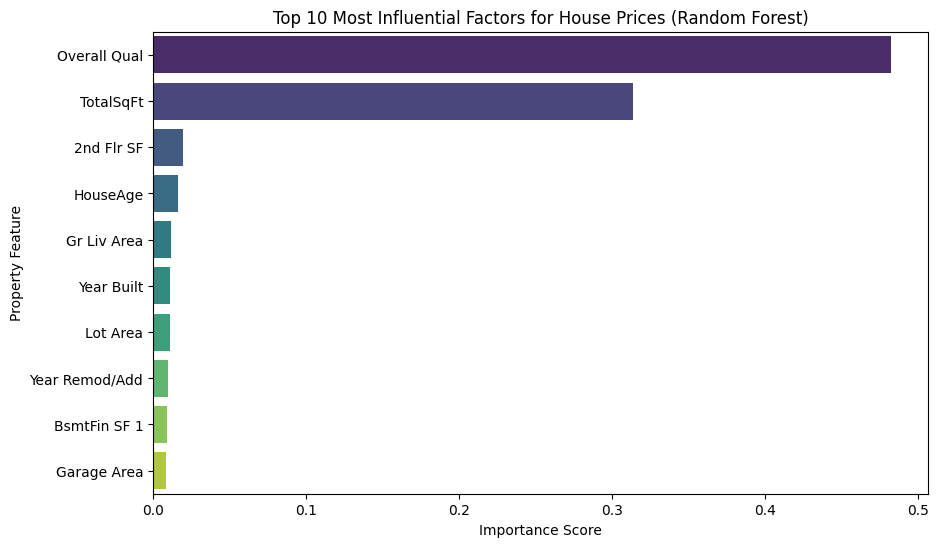

In [20]:
# --- Top 10 Feature Importances ---
# Importance scores extraction from the Random Forest model
importances = rf_model.feature_importances_

# Bind them to the column names
feature_df = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
})

# Grabbing and sorting the top 10
top_10_features = feature_df.sort_values(by='Importance', ascending=False).head(10)

# Plot the results
plt.figure(figsize=(10, 6))
sns.barplot(data=top_10_features, x='Importance', y='Feature', palette='viridis')
plt.title('Top 10 Most Influential Factors for House Prices (Random Forest)')
plt.xlabel('Importance Score')
plt.ylabel('Property Feature')
plt.show()

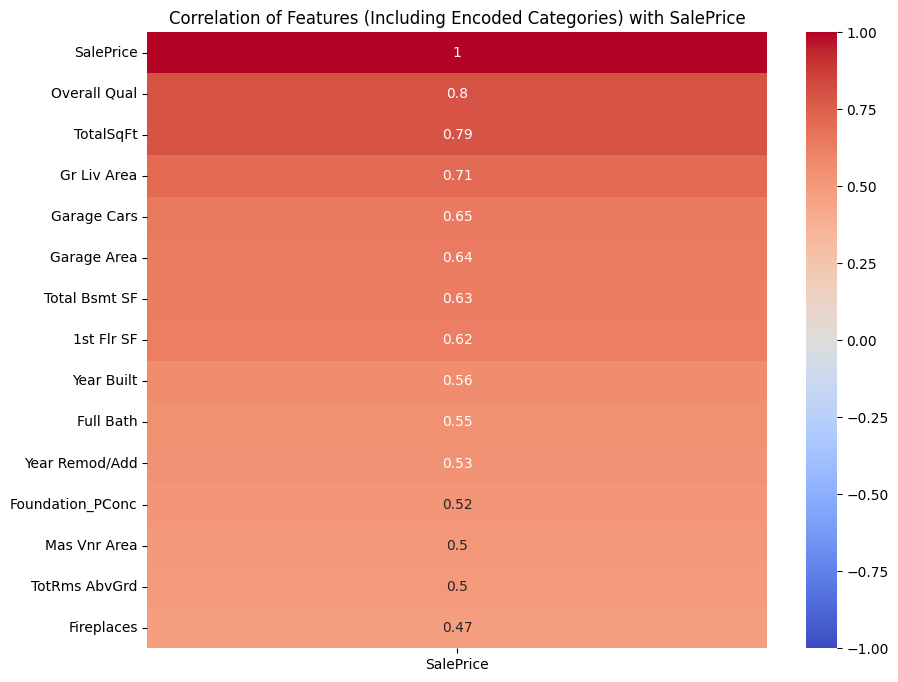

In [21]:
# Correlation Heatmap
plt.figure(figsize=(10, 8))
# Grab the top 15 features most correlated with SalePrice to keep the graph readable
top_correlations = df_ml.corr()[['SalePrice']].sort_values(by='SalePrice', ascending=False).head(15)

sns.heatmap(top_correlations, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title("Correlation of Features (Including Encoded Categories) with SalePrice")
plt.show()

# Model Evaluation & Interpretation:
Between the two architectures evaluated, the Tuned Random Forest significantly outperformed the Baseline Linear Regression model. While the Linear Regression model provided a solid baseline, it struggled to capture complex, non-linear relationships between the features.

By utilizing an ensemble of decision trees constrained to a maximum depth of 10, the Random Forest model successfully reduced both the Mean Absolute Error (MAE) and the Root Mean Squared Error (RMSE), meaning its price predictions are substantially closer to reality and suffer from fewer extreme miscalculations.

Furthermore, the higher $R^2$ score confirms the Random Forest explains a greater percentage of the variance in the housing market.

Finally, extracting the feature importances allowed us to prove that core structural variables; specifically overall quality, above-ground living area (square footage), and neighborhood; are the dominant drivers of a property's final valuation in Ames.

In [22]:
%whos

Variable                Type                     Data/Info
----------------------------------------------------------
LinearRegression        ABCMeta                  <class 'sklearn.linear_mo<...>._base.LinearRegression'>
RandomForestRegressor   ABCMeta                  <class 'sklearn.ensemble.<...>t.RandomForestRegressor'>
X                       DataFrame                      Order        PID  M<...>[2930 rows x 280 columns]
X_test                  DataFrame                      Order        PID  M<...>n[586 rows x 280 columns]
X_train                 DataFrame                      Order        PID  M<...>[2344 rows x 280 columns]
ax                      ndarray                  2: 2 elems, type `object`, 16 bytes
comparison_df           DataFrame                                         <...>45.249191        0.916686
conn                    Connection               <sqlite3.Connection object at 0x7dba434f4c70>
cursor                  Cursor                   <sqlite3.Cursor object 

In [23]:
df.to_csv("ames_cleaned.cvs", index=False)

In [24]:
import pandas as pd
predictions_df = pd.DataFrame({"SalePrice": y_test, "PredictedPrice": y_pred_rf})

predictions_df["PredictionError"] = (predictions_df["SalePrice"] - predictions_df["PredictedPrice"])

predictions_df.to_csv("ames_predictions.csv", index=False)

In [25]:
from google.colab import files

# The file was saved as .cvs in cell bRJVLcTnj0kt, so we download that name
files.download("ames_cleaned.cvs")
print("ames_cleaned.cvs downloaded successfully")

files.download("ames_predictions.csv")
print("ames_predictions.csv downloaded successfully")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ames_cleaned.cvs downloaded successfully


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

ames_predictions.csv downloaded successfully
